# AK-MCS-U vs NH-AK-MCS-U 결과 비교

`runs/gp_trial_01`의 **완료된 두 run**을 비교합니다. 두 `summary.json`이 모두 있어야 실행됩니다. 다른 실험을 보려면 아래 `RUN_DIR`만 바꾸세요.

비교 기준은 실제 한계상태함수 호출 수(`n_true_calls`)입니다. 동일 호출 수의 추이를 비교하며, 최종 결과는 양쪽 summary에서 읽습니다. `Pf`는 서로 다른 surrogate의 추정값이고, MC CoV는 **surrogate에 조건부인** 표본오차입니다. 둘 다 정확도 보증으로 해석하지 않습니다.

In [1]:
from pathlib import Path
import hashlib
import html
import json
import math

RUN_DIR = Path("runs/gp_trial_01")
MODES = {"reference": "AK-MCS-U", "nh": "NH-AK-MCS-U"}
COLORS = {"reference": "#2563eb", "nh": "#e87924"}

try:
    from IPython.display import HTML, SVG, display
except ImportError:  # 표준 Python에서 계산 검증할 때
    HTML = SVG = display = None

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def show_html(markup):
    if display is None:
        print(html.unescape(markup.replace("<tr>", "\n").replace("</td>", "  ").replace("<th>", "  ").replace("</th>", "  ").replace("</tr>", "").replace("<table>", "").replace("</table>", "")))
    else:
        display(HTML(markup))

def table(headers, rows):
    def cell(value):
        return html.escape(str(value))
    head = "".join(f"<th style='text-align:left;padding:5px 12px;border-bottom:1px solid #aaa'>{cell(v)}</th>" for v in headers)
    body = "".join("<tr>" + "".join(f"<td style='padding:4px 12px'>{cell(v)}</td>" for v in row) + "</tr>" for row in rows)
    show_html(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>")

def fmt(value, digits=5):
    if value is None:
        return "—"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, (float, int)):
        return f"{value:.{digits}f}"
    return str(value)

runs = {}
for mode in MODES:
    folder = RUN_DIR / mode
    required = ["summary.json", "evaluation.jsonl", "g_calls.jsonl", "selection.jsonl", "effective_config.json", "initial_design.json", "fixed_samples.json"]
    missing = [name for name in required if not (folder / name).is_file()]
    if missing:
        raise FileNotFoundError(f"{folder}: 완료된 run에 필요한 파일이 없습니다: {', '.join(missing)}")
    runs[mode] = {
        "summary": read_json(folder / "summary.json"),
        "evaluation": read_jsonl(folder / "evaluation.jsonl"),
        "g_calls": read_jsonl(folder / "g_calls.jsonl"),
        "selection": read_jsonl(folder / "selection.jsonl"),
        "config": read_json(folder / "effective_config.json"),
        "initial": read_json(folder / "initial_design.json"),
        "samples_hash": sha256(folder / "fixed_samples.json"),
    }
    if not runs[mode]["evaluation"]:
        raise ValueError(f"{folder}: evaluation.jsonl이 비어 있습니다.")
print(f"완료된 run 로드: {RUN_DIR} / " + ", ".join(MODES.values()))

완료된 run 로드: runs\gp_trial_01 / AK-MCS-U, NH-AK-MCS-U


## 비교 가능성 확인

두 모드의 시작 설계, MC 표본, 난수 시드와 호출 예산이 같아야 paired 비교가 성립합니다. 아래 항목이 하나라도 다르면 결과 해석에 주의하세요.

In [2]:
ref, nh = runs["reference"], runs["nh"]
checks = {
    "초기 X/Y 동일": all(ref["initial"].get(k) == nh["initial"].get(k) for k in ("X", "Y")),
    "고정 MC 표본 동일": ref["samples_hash"] == nh["samples_hash"],
    "시드 동일": ref["config"].get("seed") == nh["config"].get("seed"),
    "초기 MC 크기 동일": ref["config"]["evaluation"].get("integration_size") == nh["config"]["evaluation"].get("integration_size"),
    "true-call 예산 동일": ref["config"]["evaluation"].get("max_true_calls") == nh["config"]["evaluation"].get("max_true_calls"),
}
table(["검사", "결과"], [(name, "일치" if ok else "불일치") for name, ok in checks.items()])
if not all(checks.values()):
    print("주의: paired 조건이 완전히 일치하지 않습니다.")
for mode, run in runs.items():
    recorded = len(run["g_calls"])
    reported = run["summary"]["n_true_calls"]
    final = run["summary"]["final"]
    assert recorded == reported == final["n_true_calls"], (mode, recorded, reported, final["n_true_calls"])
    assert run["evaluation"][-1]["n_true_calls"] == reported, mode
print("호출 로그, 마지막 평가, summary의 true-call 수 일치.")

검사,결과
초기 X/Y 동일,일치
고정 MC 표본 동일,일치
시드 동일,일치
초기 MC 크기 동일,일치
true-call 예산 동일,일치


호출 로그, 마지막 평가, summary의 true-call 수 일치.


## 최종 결과

`converged`는 학습 종료 기준(min U ≥ 목표값)과 MC 정밀도 기준을 **모두** 만족한 경우입니다. `budget_exhausted`는 주어진 호출 예산에서 중단됐다는 뜻입니다.

In [3]:
stop = ref["config"]["evaluation"]["stop"]
paper = ref["config"].get("reference", {}).get("paper_example", {})
rows = []
for mode, run in runs.items():
    s, f = run["summary"], run["summary"]["final"]
    rows.append((
        MODES[mode], s["n_true_calls"], fmt(f["pf_surrogate"]), fmt(f["population_min_u"], 3),
        fmt(f["mc_cov"], 4), f["learning_converged"], f["mc_precision_met"],
        f["converged"], f["stop_reason"], fmt(s.get("wall_seconds"), 1)
    ))
table(["모드", "true calls", "Pf", "min U", "MC CoV", "학습 수렴", "MC 정밀도", "전체 수렴", "중단 이유", "시간(s)"], rows)
print(f"설정 기준: min U ≥ {stop['min_u']}, MC CoV ≤ {stop['max_mc_cov']}. 논문 표의 Pf = {paper.get('reported_pf', '—')} (참고값; 동일 재현 조건 아님).")
rf, nf = ref["summary"]["final"], nh["summary"]["final"]
print(f"NH − reference 최종 Pf = {nf['pf_surrogate'] - rf['pf_surrogate']:+.6f}; 최종 wall time = {nh['summary']['wall_seconds'] - ref['summary']['wall_seconds']:+.1f} s.")
table(["모드", "최종 theta", "optimizer", "rejected 결과", "최종 경고 수"], [
    (MODES[mode],
     ", ".join(fmt(x, 4) for x in run["summary"]["final"]["training_log"]["theta"]),
     run["summary"]["final"]["training_log"]["optimizer"],
     run["summary"]["final"]["training_log"].get("optimizer_rejected_results", "—"),
     len(run["summary"]["final"]["training_log"].get("warnings", [])))
    for mode, run in runs.items()
])

모드,true calls,Pf,min U,MC CoV,학습 수렴,MC 정밀도,전체 수렴,중단 이유,시간(s)
AK-MCS-U,500,0.07275,0.007,0.0146,False,True,False,budget_exhausted,470.7
NH-AK-MCS-U,500,0.07270,0.027,0.0146,False,True,False,budget_exhausted,481.9


설정 기준: min U ≥ 2.0, MC CoV ≤ 0.05. 논문 표의 Pf = 0.0734 (참고값; 동일 재현 조건 아님).
NH − reference 최종 Pf = -0.000050; 최종 wall time = +11.1 s.


모드,최종 theta,optimizer,rejected 결과,최종 경고 수
AK-MCS-U,"7.0846, 7.3312",DACE_boxmin,0,0
NH-AK-MCS-U,"7.2085, 7.5243",DACE_boxmin,0,0


## 동일 true-call 기준 추이

평가 로그를 `n_true_calls`에 맞춰 정렬합니다. 같은 호출 수에서 재평가가 여러 번 기록되면 마지막 값을 사용합니다. 점선은 설정된 종료 기준이며, Pf의 점선은 논문 참고값입니다. min U는 기준값 2를 포함한 전체 축과 실제 값의 변화를 보기 위한 확대 축을 모두 표시합니다.

In [4]:
def by_call(rows):
    return dict(sorted((row["n_true_calls"], row) for row in rows))

trajectories = {mode: by_call(run["evaluation"]) for mode, run in runs.items()}
common_calls = sorted(set(trajectories["reference"]) & set(trajectories["nh"]))
if not common_calls:
    raise ValueError("같은 true-call 수로 비교할 평가 결과가 없습니다.")

def line_chart(title, key, threshold=None, digits=3):
    series = []
    for mode, points in trajectories.items():
        xy = [(calls, row[key]) for calls, row in points.items()
              if isinstance(row.get(key), (int, float)) and math.isfinite(row[key])]
        series.append((mode, xy))
    all_xy = [xy for _, points in series for xy in points]
    if not all_xy:
        print(f"{title}: 유효한 값이 없습니다.")
        return
    x0, x1 = min(x for x, _ in all_xy), max(x for x, _ in all_xy)
    ys = [y for _, y in all_xy] + ([threshold] if threshold is not None else [])
    y0, y1 = min(ys), max(ys)
    margin = (y1 - y0) * 0.08 or max(abs(y1), 1) * 0.08
    y0, y1 = y0 - margin, y1 + margin
    W, H, L, R, T, B = 800, 300, 68, 18, 34, 42
    plot_w, plot_h = W - L - R, H - T - B
    sx = lambda x: L + (x - x0) / (x1 - x0 or 1) * plot_w
    sy = lambda y: T + (y1 - y) / (y1 - y0) * plot_h
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{W}" height="{H}" viewBox="0 0 {W} {H}" role="img" aria-label="{html.escape(title)}">',
             f'<text x="{L}" y="20" font-size="16" font-family="sans-serif">{html.escape(title)}</text>',
             f'<line x1="{L}" y1="{T}" x2="{L}" y2="{H-B}" stroke="#777"/>',
             f'<line x1="{L}" y1="{H-B}" x2="{W-R}" y2="{H-B}" stroke="#777"/>']
    for i in range(5):
        y = y0 + (y1 - y0) * i / 4
        py = sy(y)
        parts.append(f'<line x1="{L}" y1="{py:.1f}" x2="{W-R}" y2="{py:.1f}" stroke="#eee"/>')
        parts.append(f'<text x="{L-7}" y="{py+4:.1f}" text-anchor="end" font-size="11" font-family="sans-serif">{y:.{digits}f}</text>')
        x = x0 + (x1 - x0) * i / 4
        parts.append(f'<text x="{sx(x):.1f}" y="{H-B+17}" text-anchor="middle" font-size="11" font-family="sans-serif">{x:.0f}</text>')
    parts.append(f'<text x="{W/2}" y="{H-4}" text-anchor="middle" font-size="12" font-family="sans-serif">true calls</text>')
    if threshold is not None:
        py = sy(threshold)
        parts.append(f'<line x1="{L}" y1="{py:.1f}" x2="{W-R}" y2="{py:.1f}" stroke="#666" stroke-dasharray="6 4"/>')
    for mode, xy in series:
        if not xy:
            continue
        points = " ".join(f"{sx(x):.1f},{sy(y):.1f}" for x, y in xy)
        parts.append(f'<polyline points="{points}" fill="none" stroke="{COLORS[mode]}" stroke-width="2"/>')
    for i, (mode, _) in enumerate(series):
        lx = L + i * 190
        parts.append(f'<line x1="{lx}" y1="{T+10}" x2="{lx+22}" y2="{T+10}" stroke="{COLORS[mode]}" stroke-width="3"/>')
        parts.append(f'<text x="{lx+27}" y="{T+14}" font-size="12" font-family="sans-serif">{MODES[mode]}</text>')
    parts.append("</svg>")
    svg = "".join(parts)
    if display is None:
        print(f"{title}: {len(all_xy)} points, x={x0}..{x1}, y={min(ys):.{digits}f}..{max(ys):.{digits}f}")
    else:
        display(SVG(svg))
    return svg

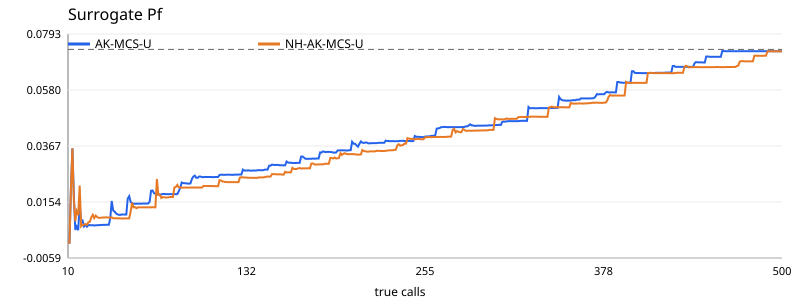

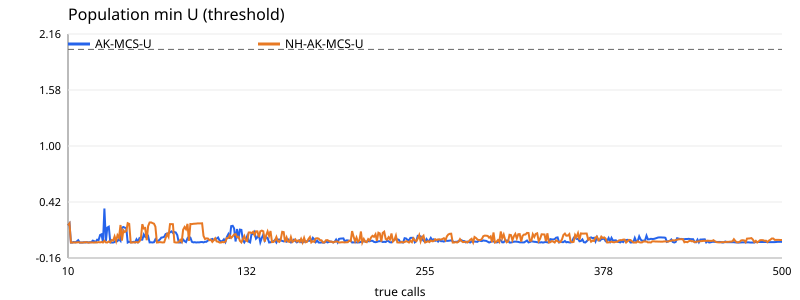

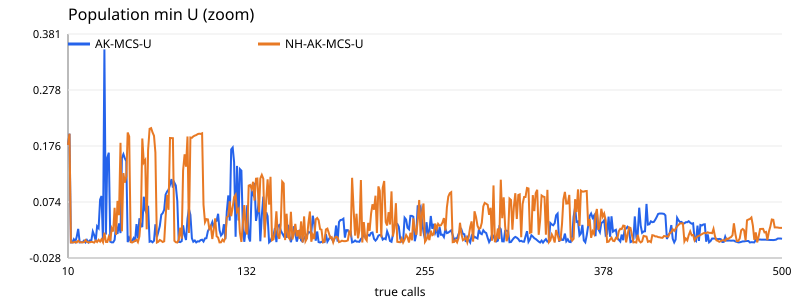

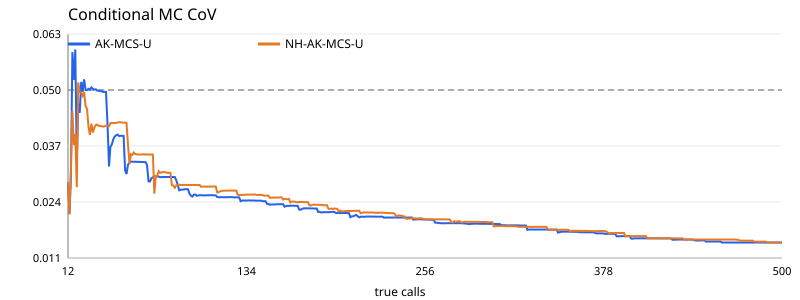

In [5]:
pf_svg = line_chart("Surrogate Pf", "pf_surrogate", paper.get("reported_pf"), 4)
u_svg = line_chart("Population min U (threshold)", "population_min_u", stop["min_u"], 2)
u_zoom_svg = line_chart("Population min U (zoom)", "population_min_u", None, 3)
cov_svg = line_chart("Conditional MC CoV", "mc_cov", stop["max_mc_cov"], 3)

## 같은 예산에서 직접 비교

최종 호출 수가 같더라도, 아래 표는 두 평가 로그에 공통으로 존재하는 호출 수만 사용합니다. `Δ Pf`와 `Δ min U`는 NH − reference입니다.

In [6]:
milestones = sorted(set([common_calls[0], common_calls[len(common_calls)//4], common_calls[len(common_calls)//2], common_calls[3*len(common_calls)//4], common_calls[-1]]))
table(["true calls", "reference Pf", "NH Pf", "Δ Pf", "reference min U", "NH min U", "Δ min U"], [
    (n,
     fmt(trajectories["reference"][n]["pf_surrogate"]),
     fmt(trajectories["nh"][n]["pf_surrogate"]),
     fmt(trajectories["nh"][n]["pf_surrogate"] - trajectories["reference"][n]["pf_surrogate"]),
     fmt(trajectories["reference"][n]["population_min_u"], 3),
     fmt(trajectories["nh"][n]["population_min_u"], 3),
     fmt(trajectories["nh"][n]["population_min_u"] - trajectories["reference"][n]["population_min_u"], 3))
    for n in milestones
])

true calls,reference Pf,NH Pf,Δ Pf,reference min U,NH min U,Δ min U
10,0.00000,0.00000,0.00000,0.178,0.178,0.000
132,0.02740,0.02472,-0.00268,0.028,0.022,-0.006
255,0.04028,0.04002,-0.00027,0.005,0.001,-0.004
378,0.05640,0.05318,-0.00322,0.041,0.053,0.012
500,0.07275,0.07270,-0.00005,0.007,0.027,0.020


## 해석 메모

- 최종 `Pf` 차이가 작더라도 이것만으로 어느 방법이 더 정확한지는 알 수 없습니다. 이 실험에는 정확한 `Pf`나 독립 검증값이 기록되지 않았습니다.
- `min U < 2`이면 지정한 학습 수렴 기준을 만족하지 못한 것입니다. 호출 예산에 도달해 끝난 것과 수렴은 구분해야 합니다.
- 논문의 `Pf=0.0734`와 호출 수는 참고선입니다. 현재 설정의 초기 설계·최적화 등은 논문의 엄밀한 재현 조건과 다릅니다.
- 단일 seed의 paired 결과입니다. NH의 평균적 우위나 안정성을 주장하려면 여러 seed의 독립 반복이 필요합니다.